# Демо 1. Ембединги й семантичний пошук

У цьому ноутбуці перетворюємо тексти на **ембединги**. Ембединги — це вектори, у які перетворюються тексти таким чином, що близькі за значенням тексти мають вектори близькі за розміщенням у векторному просторі. На базі цієї властивості будуємо семантичний пошук. З метою навчання робимо це без жодних спеціалізованих бібліотек,
використовуємо лише `numpy`.

Документи для пошуку — нормативні документи Житомирської політехніки з [docs.ztu.edu.ua](https://docs.ztu.edu.ua/):
положення про оцінювання, гуртожитки, стипендії, старосту академічної групи тощо.
Мовна модель, яка потім буде використовуватися для генерації, швидше за все не бачила цих документів під час тренування, тому відповісти на питання про них
вона зможе лише тоді, коли потрібний фрагмент документа буде знайдено й передано їй у промпті.
Пошук потрібних фрагментів документа і є першою половиною RAG.

_Зверніть увагу: ноутбук працює і на CPU, але з GPU ембединги рахуються швидше._

In [2]:
# sentence-transformers — бібліотека для обчислення ембедингів текстів, pypdf — витягування тексту з PDF
!pip install -q "sentence-transformers>=5" pypdf

In [3]:
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")

Пристрій: cuda


## 1. Модель ембедингів

Для перетворення текстових фрагментів на ембединги використовують спеціальні ембедингові моделі. [Qwen3-Embedding-0.6B](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B) — багатомовна модель ембедингів із сімʼї моделей Qwen3. Вона перетворює текст довжиною до ~32 тис. токенів на вектор
із 1024 чисел. Ці два числа: максимальний розмір вхідного тексту і розмірність результуючого ембедингу - є важливими характеристиками ембедингових моделей.

In [4]:
EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-0.6B"
dtype = torch.float16 if device == "cuda" else torch.float32
model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=device, model_kwargs={"dtype": dtype})

print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")
print(f"Максимальна довжина тексту в токенах: {model.max_seq_length}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.2k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

Розмірність ембедингу: 1024
Максимальна довжина тексту в токенах: 32768


/tmp/ipykernel_319/1793327947.py:5: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")


## 2. Ембединг одного речення

Незалежно від довжини тексту модель повертає вектор однакової розмірності.
Параметр `normalize_embeddings=True` ділить вектор на його евклідову ($L_{2}$) норму. Формула евклідової норми:

$$
\|\vec{x}\|_{2} = \sqrt{\sum_{i=1}^{n}x_{i}^{2}}
$$


Таким чином довжина (норма) вектора дорівнює 1.
Так косинусна подібність, яку потім потрібно часто підраховувати, зводиться до скалярного добутку.

In [5]:
sentence = "Чому я такий розумний?"
embedding = model.encode(sentence, normalize_embeddings=True)

print(f"Форма: {embedding.shape}")
print(f"Перші 8 чисел: {embedding[:8]}")
print(f"Евклідова норма вектора: {np.linalg.norm(embedding):.4f}")

# Загалом модель сама нормалізує вектор всередині,
# тому `normalize_embeddings=True` є зайвим у цьому конкретному випадку
# зверніть увагу на останній шар моделі
print(model)

Форма: (1024,)
Перші 8 чисел: [-0.02551   -0.09235   -0.0002925  0.02061    0.007275   0.0573
 -0.0488     0.04395  ]
Евклідова норма вектора: 1.0000
SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'Qwen3Model'})
  (1): Pooling({'embedding_dimension': 1024, 'pooling_mode': 'lasttoken', 'include_prompt': True})
  (2): Normalize({})
)


## 3. Косинусна подібність

Близькість двох ембедингів вимірюють **косинусом кута** між ними:

$$\cos(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}$$

Значення `1` означає однаковий напрям векторів, `0` — ортогональні вектори, `-1` - вектори вказують у повністю протилежні сторони.
Для нормалізованих векторів знаменник дорівнює 1, і косинус дорівнює скалярному добутку.
Порахуємо його вручну й порівняємо з вбудованим методом `model.similarity`.

In [6]:
a, b, c = model.encode(
    ["Скільки коштує проживання в гуртожитку?",
     "Яка плата за місце в студентському гуртожитку?",
     "Чому Політехніка краще за Гарвард?"],
    normalize_embeddings=True,
)

manual = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
with_library = model.similarity(a, b).item()

print(f"Вручну (a <=> b):     {manual:.4f}")
print(f"Бібліотека (a <=> b): {with_library:.4f}")

print(f"Бібліотека (a <=> c): {model.similarity(a, c).item():.4f}")

Вручну (a <=> b):     0.6489
Бібліотека (a <=> b): 0.6489
Бібліотека (a <=> c): 0.2329


In [7]:
# Оскільки, як зазначалося вище, ембединги є зазвичай нормалізованими векторами, то знаменник дорівнює `1`.
# Перевіримо це:
print(f"Норма a: {np.linalg.norm(a):.4f}")
print(f"Норма b: {np.linalg.norm(b):.4f}")
print(f"Норма c: {np.linalg.norm(c):.4f}")

Норма a: 1.0000
Норма b: 1.0000
Норма c: 1.0000


In [8]:
# Зважаючи на це ми можемо опускати нижню частину формули косинусної подібності
# і вираховувати її лише як скалярний добуток двох векторів

pure_dot_product = np.dot(a, b)
vector_norm_product = np.linalg.norm(a) * np.linalg.norm(b)

assert round(pure_dot_product, 4) == round(manual, 4) == round(with_library, 4), "The teacher made a mistake!"
assert np.isclose(vector_norm_product, 1), "The teacher doesn't know math"

### Косинусна подібність на простих векторах

Ембединг має 1024 виміри, але формула однакова для будь-якої розмірності.
Розглянемо її на двовимірних векторах, які можна намалювати. Вектор $a = (3, 1)$ порівнюємо з чотирма іншими:
- $e = (6, 2)$ — той самий напрям, але вдвічі довший;
- $b = (2, 2)$ — близький напрям;
- $c = (-1, 3)$ — перпендикулярний напрям;
- $d = (-3, -1)$ — протилежний напрям.

a·e =   20   ‖a‖·‖e‖ = 20.00   cos =  1.00   кут =   0.0°
a·b =    8   ‖a‖·‖b‖ =  8.94   cos =  0.89   кут =  26.6°
a·c =    0   ‖a‖·‖c‖ = 10.00   cos =  0.00   кут =  90.0°
a·d =  -10   ‖a‖·‖d‖ = 10.00   cos = -1.00   кут = 180.0°


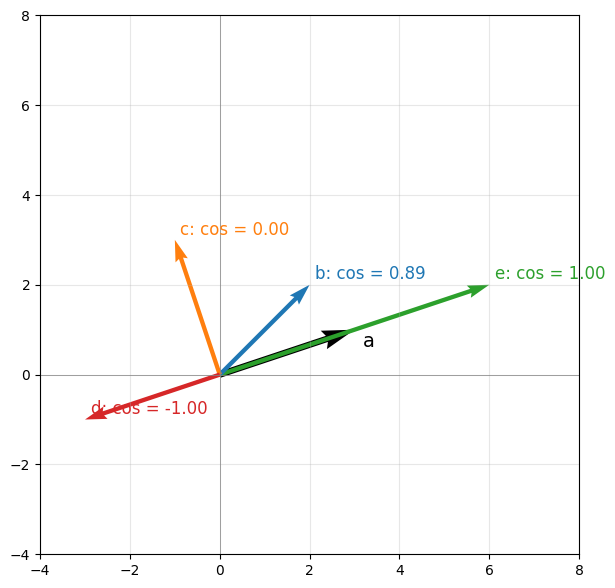

In [9]:
a2 = np.array([3, 1])
others = {
    "e": np.array([6, 2]),
    "b": np.array([2, 2]),
    "c": np.array([-1, 3]),
    "d": np.array([-3, -1]),
}


def cosine(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))


for name, v in others.items():
    dot = np.dot(a2, v)
    norms = np.linalg.norm(a2) * np.linalg.norm(v)
    angle = np.degrees(np.arccos(np.clip(cosine(a2, v), -1, 1)))
    print(f"a·{name} = {dot:4}   ‖a‖·‖{name}‖ = {norms:5.2f}   cos = {dot / norms:5.2f}   кут = {angle:5.1f}°")

fig, ax = plt.subplots(figsize=(7, 7))
ax.quiver(0, 0, *a2, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, *v, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(f"{name}: cos = {cosine(a2, v):.2f}", v, xytext=(4, 4), textcoords="offset points",
                fontsize=12, color=color)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-4, 8)
ax.set_ylim(-4, 8)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Косинус залежить лише від кута між векторами, а не від їхньої довжини: вектор $e$ удвічі довший за $a$,
але косинус дорівнює 1. Знаменник формули саме й прибирає вплив довжини.

Тепер нормалізуємо всі вектори — поділимо кожен на його довжину. Кінці нормалізованих векторів лежать
на колі радіуса 1, напрями не змінюються, а скалярний добуток дорівнює косинусу без жодного ділення.

e = [0.949 0.316]   довжина = 1.00   скалярний добуток =  1.00   cos =  1.00
b = [0.707 0.707]   довжина = 1.00   скалярний добуток =  0.89   cos =  0.89
c = [-0.316  0.949]   довжина = 1.00   скалярний добуток =  0.00   cos =  0.00
d = [-0.949 -0.316]   довжина = 1.00   скалярний добуток = -1.00   cos = -1.00


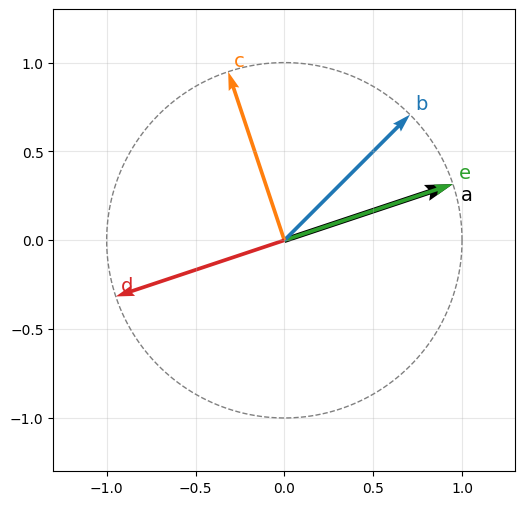

In [10]:
def normalize(v):
    return v / np.linalg.norm(v)


a2_unit = normalize(a2)
for name, v in others.items():
    v_unit = normalize(v)
    print(f"{name} = {np.round(v_unit, 3)}   довжина = {np.linalg.norm(v_unit):.2f}   "
          f"скалярний добуток = {np.dot(a2_unit, v_unit):5.2f}   cos = {cosine(a2, v):5.2f}")

fig, ax = plt.subplots(figsize=(6, 6))
circle = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(circle), np.sin(circle), color="grey", lw=1, ls="--")
ax.quiver(0, 0, *a2_unit, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2_unit, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    v_unit = normalize(v)
    ax.quiver(0, 0, *v_unit, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(name, v_unit, xytext=(4, 4), textcoords="offset points", fontsize=14, color=color)
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Вектори $a$ і $e$ після нормалізації збіглися: однаковий напрям — однаковий нормалізований вектор.

### Три виміри

У трьох вимірах усе так само: кожна компонента вектора — окрема вісь, скалярний добуток — сума
трьох попарних добутків. Нехай компоненти означають, наскільки текст стосується трьох тем:
гуртожитку, стипендії й погоди.

«плата за гуртожиток» і «заселення в гуртожиток»: a·b = 0.9·0.8 + 0.3·0.1 + 0.0·0.1 = 0.75, cos = 0.97
«плата за гуртожиток» і «стипендія»: a·b = 0.9·0.2 + 0.3·0.9 + 0.0·0.0 = 0.45, cos = 0.51
«плата за гуртожиток» і «погода»: a·b = 0.9·0.0 + 0.3·0.1 + 0.0·0.9 = 0.03, cos = 0.03


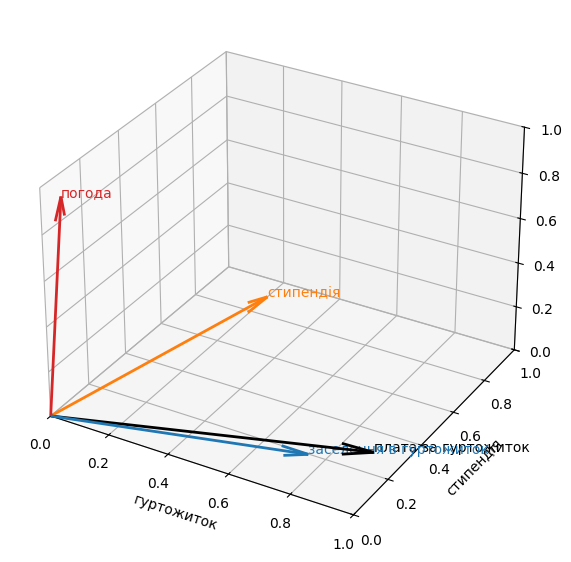

In [11]:
vectors_3d = {
    "плата за гуртожиток": np.array([0.9, 0.3, 0.0]),
    "заселення в гуртожиток": np.array([0.8, 0.1, 0.1]),
    "стипендія": np.array([0.2, 0.9, 0.0]),
    "погода": np.array([0.0, 0.1, 0.9]),
}
names_3d = list(vectors_3d)
query_3d = vectors_3d[names_3d[0]]
for name in names_3d[1:]:
    v = vectors_3d[name]
    products = " + ".join(f"{x:.1f}·{y:.1f}" for x, y in zip(query_3d, v))
    print(f"«{names_3d[0]}» і «{name}»: a·b = {products} = {np.dot(query_3d, v):.2f}, cos = {cosine(query_3d, v):.2f}")

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
for (name, v), color in zip(vectors_3d.items(), ["black", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, 0, *v, color=color, arrow_length_ratio=0.1, linewidth=2)
    ax.text(*v, name, color=color, fontsize=10)
ax.set_xlabel("гуртожиток")
ax.set_ylabel("стипендія")
ax.set_zlabel("погода")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_zlim(0, 1)
plt.show()

Справжній ембединг влаштований так само, лише замість трьох осей — 1024. На відміну від цього прикладу,
окремі виміри ембединга не мають зрозумілого людині змісту: значення має лише напрям вектора в цілому.

## 4. Матриця подібності

Порахуємо подібність кожного речення з кожним. Серед речень є:
- дві пари перефразувань (про плату за гуртожиток і про стипендію);
- два речення зі спільним словом «ключ», але різним змістом;
- речення, не повʼязане з рештою.

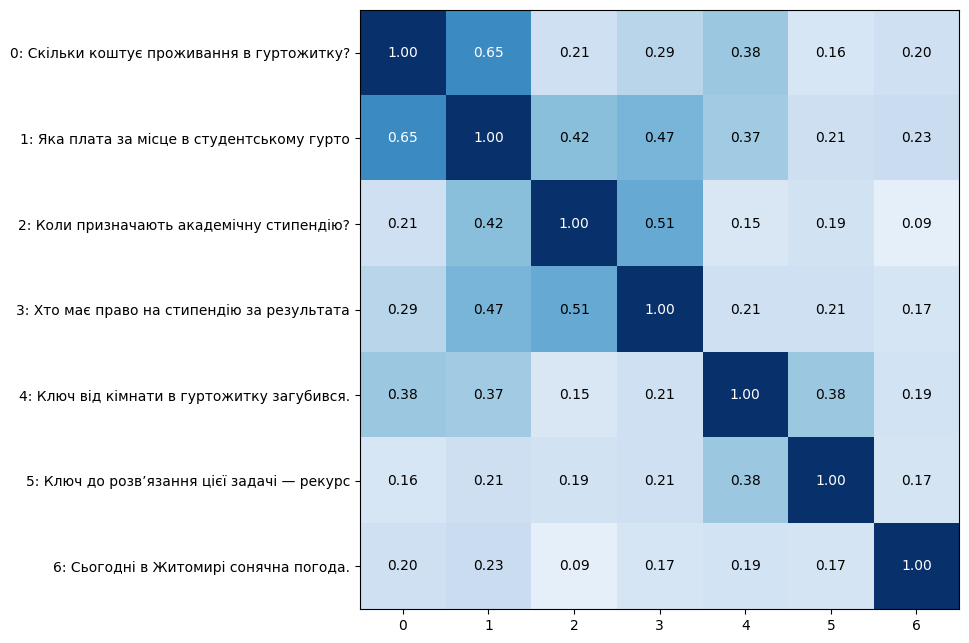

In [12]:
def show_similarity_matrix(sentences, figsize=(9, 7)):
  embeddings = model.encode(sentences, normalize_embeddings=True)
  similarity = embeddings @ embeddings.T

  fig, ax = plt.subplots(figsize=figsize)
  ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)
  ax.set_xticks(range(len(sentences)), [f"{i}" for i in range(len(sentences))])
  ax.set_yticks(range(len(sentences)), [f"{i}: {s[:40]}" for i, s in enumerate(sentences)])
  for i in range(len(sentences)):
      for j in range(len(sentences)):
          ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center",
                  color="white" if similarity[i, j] > 0.6 else "black")
  plt.tight_layout()
  plt.show()

uni_sentences = [
    "Скільки коштує проживання в гуртожитку?",
    "Яка плата за місце в студентському гуртожитку?",
    "Коли призначають академічну стипендію?",
    "Хто має право на стипендію за результатами сесії?",
    "Ключ від кімнати в гуртожитку загубився.",
    "Ключ до розвʼязання цієї задачі — рекурсія.",
    "Сьогодні в Житомирі сонячна погода.",
]

show_similarity_matrix(uni_sentences)


Перефразування мають найвищу подібність, хоча містять лише одне спільне слово, так само як і пара з речень 4-5, схожість яких вдвічі менша.
Водночас подібність ніколи не падає до нуля: навіть речення про погоду має з рештою додатну подібність.

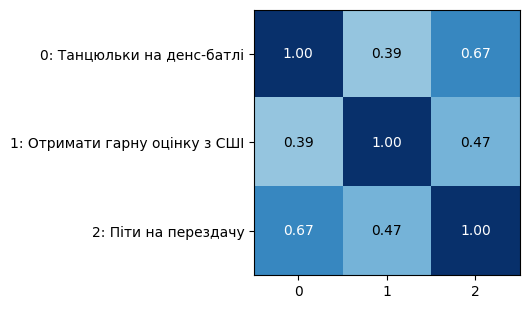

In [13]:
# Пограємося, вимірюючи подібність цілком випадкових і взагалі не придуманих викладачем фраз

pseudo_random_sentences = [
    "Танцюльки на денс-батлі",
    "Отримати гарну оцінку з СШІ",
    "Піти на перездачу"
]

show_similarity_matrix(pseudo_random_sentences, figsize=(5, 4))


## 5. Тексти на площині

Вектор із 1024 чисел неможливо намалювати, тому проєктуємо ембединги на площину методом головних компонент (Principal Component Analysis, PCA).
Проєкція втрачає більшу частину інформації, але групи речень на одну тему видно й на ній.

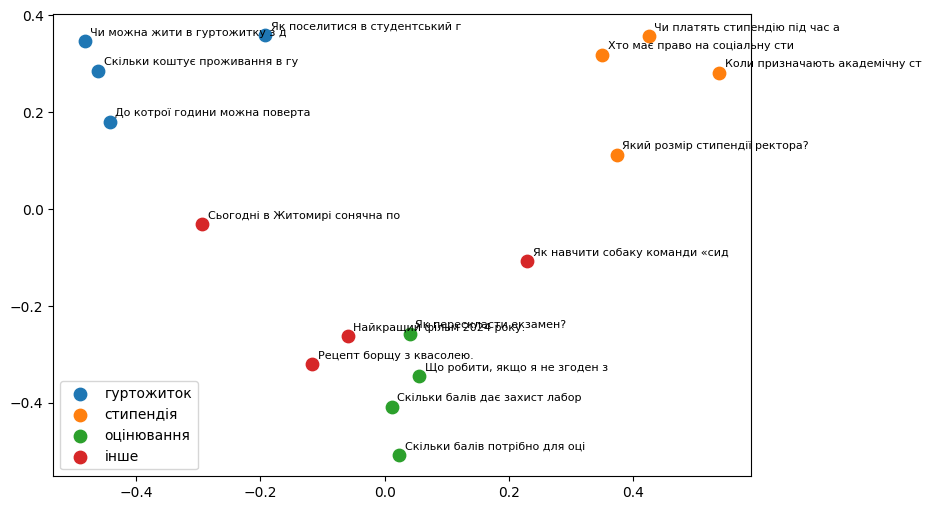

In [14]:
topics = {
    "гуртожиток": [
        "Скільки коштує проживання в гуртожитку?",
        "Як поселитися в студентський гуртожиток?",
        "До котрої години можна повертатися в гуртожиток?",
        "Чи можна жити в гуртожитку з дружиною?",
    ],
    "стипендія": [
        "Коли призначають академічну стипендію?",
        "Хто має право на соціальну стипендію?",
        "Який розмір стипендії ректора?",
        "Чи платять стипендію під час академічної відпустки?",
    ],
    "оцінювання": [
        "Скільки балів потрібно для оцінки «відмінно»?",
        "Що робити, якщо я не згоден з оцінкою?",
        "Як перескласти екзамен?",
        "Скільки балів дає захист лабораторної роботи?",
    ],
    "інше": [
        "Сьогодні в Житомирі сонячна погода.",
        "Рецепт борщу з квасолею.",
        "Найкращий фільм 2024 року.",
        "Як навчити собаку команди «сидіти»?",
    ],
}
texts = [t for group in topics.values() for t in group]
labels = [name for name, group in topics.items() for _ in group]
points = model.encode(texts, normalize_embeddings=True).astype(np.float32)

centered = points - points.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
xy = centered @ vt[:2].T

fig, ax = plt.subplots(figsize=(9, 6))
for name in topics:
    mask = np.array(labels) == name
    ax.scatter(xy[mask, 0], xy[mask, 1], s=80, label=name)
for (x, y), t in zip(xy, texts):
    ax.annotate(t[:30], (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.legend()
plt.show()

## 6. Запит і документ кодуються по-різному

Короткий запит («до якої дати платити?») і фрагмент документа, що містить відповідь, — тексти різного вигляду.
Тому багато моделей ембедингів додають до запиту інструкцію. Qwen3-Embedding зберігає її у промпті `query`,
а документи кодує без інструкції.

In [15]:
print(repr(model.prompts["query"]))
print(repr(model.prompts["document"]))

'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'
''


In [16]:
passages = [
    "Студент вносить авансовий платіж за 1 семестр до 1 вересня, а за 2 семестр – до 1 лютого.",
    "З 23:00 години і до 7:00 години в гуртожитку повинна додержуватись тиша.",
    "Вибори старости академічної групи на 1 курсі відбуваються після двох тижнів навчального процесу.",
    "Оцінка «добре» (B за шкалою ЄКТС) відповідає 82–89 балам.",
]
queries = [
    "До якої дати платити за гуртожиток?",
    "Коли в гуртожитку не можна шуміти?",
    "Коли обирають старосту?",
    "Скільки балів на B?",
]
passage_embeddings = model.encode(passages, normalize_embeddings=True)

np.set_printoptions(precision=2, suppress=True)
for prompt_name in [None, "query"]:
    query_embeddings = model.encode(queries, normalize_embeddings=True, prompt_name=prompt_name)
    print(f"Промпт запиту: {prompt_name}")
    print(query_embeddings @ passage_embeddings.T, "\n")

Промпт запиту: None
[[0.44 0.52 0.28 0.15]
 [0.17 0.69 0.22 0.15]
 [0.15 0.11 0.43 0.15]
 [0.2  0.16 0.16 0.38]] 

Промпт запиту: query
[[0.51 0.61 0.33 0.18]
 [0.2  0.76 0.24 0.15]
 [0.2  0.14 0.45 0.17]
 [0.19 0.17 0.17 0.4 ]] 



Рядки — запити, стовпці — фрагменти; на діагоналі стоїть правильна пара.

## 7. Документи університету

Завантажуємо 14 документів із сайту університету й витягуємо з них текст бібліотекою `pypdf`.
Серед них дві версії Положення про оцінювання — чинна і стара — та дві редакції освітньої програми
«Інженерія програмного забезпечення». Такі дублікати з різними даними типові для реальних баз документів.

In [17]:
BASE_URL = "https://docs.ztu.edu.ua/"
DOCUMENTS = [
    ("275", "Положення про оцінювання результатів навчання (чинна версія 4.0)", {"mdocs-file": 275}),
    ("275-v3.1", "Положення про оцінювання результатів навчання (стара версія 3.1)",
     {"mdocs-version": "polozhennja pro ocinjuvannja znan yekts_nove.pdf-v3.1", "mdocs-file": 275, "mdocs-url": "false"}),
    ("277", "Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін", {"mdocs-file": 277}),
    ("291", "Положення про проведення практики здобувачів вищої освіти", {"mdocs-file": 291}),
    ("340", "Правила призначення академічних стипендій", {"mdocs-file": 340}),
    ("344", "Положення про стипендію ректора", {"mdocs-file": 344}),
    ("348", "Положення про користування гуртожитками", {"mdocs-file": 348}),
    ("1219", "Правила внутрішнього розпорядку в студентських гуртожитках", {"mdocs-file": 1219}),
    ("1199", "Кодекс академічної доброчесності", {"mdocs-file": 1199}),
    ("4389", "Положення про студентського омбудсмана", {"mdocs-file": 4389}),
    ("336", "Положення про старосту академічної групи", {"mdocs-file": 336}),
    ("3320", "ОПП F2 «Інженерія програмного забезпечення» (бакалавр), редакція 2025 року", {"mdocs-file": 3320}),
    ("3329", "ОПП 121 «Інженерія програмного забезпечення» (бакалавр), редакція 2024 року", {"mdocs-file": 3329}),
    ("283", "Положення про переведення здобувачів вищої освіти", {"mdocs-file": 283}),
]


PDF_DIR = Path("ztu_pdfs")
PDF_DIR.mkdir(exist_ok=True)


def fetch(params, attempts=3):
    # Сайт іноді обриває зʼєднання, тому пробуємо кілька разів
    for attempt in range(attempts):
        try:
            response = requests.get(BASE_URL, params=params, timeout=120)
            response.raise_for_status()
            return response.content
        except requests.RequestException:
            if attempt == attempts - 1:
                raise
            time.sleep(5)


def download_pdf(doc_id, params):
    # Зберігаємо PDF на диск, щоб під час повторного запуску не завантажувати їх знову
    path = PDF_DIR / f"{doc_id}.pdf"
    if not path.exists():
        path.write_bytes(fetch(params))
    return PdfReader(path)

### Колонтитули

Кожна сторінка цих документів починається з однакового колонтитула системи управління якістю
(назва університету, код документа, номер аркуша). Прибираємо рядки колонтитула регулярним виразом.
Оформлення колонтитула в різних документах трохи відрізняється (регістр, формат коду документа), тому вираз
нечутливий до регістру й перевіряє лише перші 12 рядків сторінки, щоб не зачепити числа в таблицях.

In [18]:
HEADER_LINE = re.compile(
    r"^(Житомирська|політехніка|Міністерство освіти.*|Державний університет «Житомирська політехніка»|"
    r"Система управління якістю.*|П[\s\-–]*[CС]?[АA]?[ГG]?[\s\d.\-–]*|[\d.\-–\s/_]+|Випуск.*)$",
    re.IGNORECASE,
)
HEADER_LINES = 12


def page_text(page):
    lines = (page.extract_text() or "").split("\n")
    head = [line for line in lines[:HEADER_LINES] if not HEADER_LINE.match(line.strip())]
    return " ".join(head + lines[HEADER_LINES:])


reader = download_pdf("336", {"mdocs-file": 336})
print("До очищення:\n", reader.pages[2].extract_text()[:400])
print("\nПісля очищення:\n", page_text(reader.pages[2])[:400])

До очищення:
 Житомирська 
політехніка 
Міністерство освіти і науки України 
Державний університет «Житомирська політехніка» 
П CАГ – 44 – 15 – 02 – 
2019 
Випуск 2 Зміни 1 Екземпляр № 2 Арк   8/__ 
 
 3 
 
1. ЗАГАЛЬНІ ПОЛОЖЕННЯ 
1.1. Старостою академічної групи може бути студент, якому притаманні високі 
моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив 
на колектив гру

Після очищення:
     1. ЗАГАЛЬНІ ПОЛОЖЕННЯ  1.1. Старостою академічної групи може бути студент, якому притаманні високі  моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив  на колектив групи та володіє організаторськими здібностями.  1.2. Староста студентської академічної групи обирається як представник деканату для  організаційного забезпечення навчального процесу в академі


### Документи без текстового шару

Частина PDF — це відскановані сторінки: замість тексту в них зображення, і `pypdf` нічого не витягує.
Для таких документів потрібне розпізнавання тексту (OCR); у цьому демо ми їх просто пропускаємо.

In [19]:
MIN_CHARS_PER_PAGE = 100


def document_text(reader):
    return re.sub(r"\s+", " ", " ".join(page_text(page) for page in reader.pages)).strip()


def is_scan(text, reader):
    return len(text) < MIN_CHARS_PER_PAGE * len(reader.pages)


documents = {}
for doc_id, title, params in DOCUMENTS:
    reader = download_pdf(doc_id, params)
    text = document_text(reader)
    if is_scan(text, reader):
        print(f"{doc_id}: текстового шару немає, потрібне OCR — пропущено")
        continue
    documents[doc_id] = {"title": title, "text": text}
    print(f"{doc_id}: {len(reader.pages)} сторінок, {len(text)} символів — {title}")

275: 23 сторінок, 24944 символів — Положення про оцінювання результатів навчання (чинна версія 4.0)
275-v3.1: 13 сторінок, 10505 символів — Положення про оцінювання результатів навчання (стара версія 3.1)
277: 16 сторінок, 15945 символів — Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
291: 17 сторінок, 14603 символів — Положення про проведення практики здобувачів вищої освіти
340: 30 сторінок, 35706 символів — Правила призначення академічних стипендій
344: 10 сторінок, 2455 символів — Положення про стипендію ректора
348: 22 сторінок, 25608 символів — Положення про користування гуртожитками
1219: 12 сторінок, 9159 символів — Правила внутрішнього розпорядку в студентських гуртожитках
1199: 37 сторінок, 56918 символів — Кодекс академічної доброчесності
4389: 18 сторінок, 20685 символів — Положення про студентського омбудсмана
336: 8 сторінок, 3560 символів — Положення про старосту академічної групи
3320: 16 сторінок, 31670 символів — ОПП F2 «Інженері

## 8. Пошук вручну

Цілий документ задовгий для одного ембединга: у вектор із 1024 чисел не вміститься зміст 30 сторінок.
Тому ділимо кожен документ на **фрагменти** по 1000 символів, що перекриваються на 200 символів,
щоб речення на межі потрапило хоча б в один фрагмент повністю. Зверніть увагу, це не є найоптимальнішим способом для таких документів. Способи розбиття детально розглядаємо в демо 2.

In [20]:
CHUNK_SIZE, OVERLAP = 1000, 200

chunks = []
for doc_id, doc in documents.items():
    text = doc["text"]
    for start in range(0, len(text), CHUNK_SIZE - OVERLAP):
        chunks.append({"doc_id": doc_id, "text": text[start:start + CHUNK_SIZE]})

print(f"Фрагментів: {len(chunks)}")
start = time.time()
chunk_embeddings = model.encode([c["text"] for c in chunks], normalize_embeddings=True,
                                batch_size=16, show_progress_bar=True)
print(f"Ембединги пораховано за {time.time() - start:.1f} с, форма матриці: {chunk_embeddings.shape}")

Фрагментів: 361


Batches:   0%|          | 0/23 [00:00<?, ?it/s]

Ембединги пораховано за 18.3 с, форма матриці: (361, 1024)


Увесь пошук — це одне множення матриці фрагментів на вектор запиту й сортування результатів.

In [21]:
def search(query, embeddings, k=3):
    query_embedding = model.encode(query, normalize_embeddings=True, prompt_name="query")
    scores = embeddings @ query_embedding
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top]


def show(query, embeddings, k=3):
    print(f"Запит: {query}")
    for i, score in search(query, embeddings, k):
        chunk = chunks[i]
        print(f"  {score:.2f}  [{chunk['doc_id']}] {documents[chunk['doc_id']]['title']}")
        print(f"        {chunk['text'][:150]}…")
    print()


show("Коли обирають старосту на першому курсі?", chunk_embeddings)
show("Хто такий студентський омбудсман?", chunk_embeddings)

Запит: Коли обирають старосту на першому курсі?
  0.57  [336] Положення про старосту академічної групи
         ректоратом або за їх дорученням. У своїй роботі староста академічної групи співпрацює з куратором та ментором групи. 1.3. У виборах старости студентс…
  0.50  [4389] Положення про студентського омбудсмана
        ємодіє з Молодіжною радою при Житомирській обласній державній (військовій) адміністрації та іншими консультативно-дорадчими органами молодіжної політи…
  0.50  [277] Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
        нсульт Максим ОСТАПЧУК __.__.20__ Додаток 1 до Положення про порядок та умови обрання здобувачами вищої освіти вибіркових дисциплін (пункт 2.4.) Декан…

Запит: Хто такий студентський омбудсман?
  0.71  [4389] Положення про студентського омбудсмана
        ЗАТВЕРДЖЕНО Наказ Державного університету «Житомирська політехніка» 28 вересня 2026 р. № 453/од ПОЛОЖЕННЯ про студентського омбудсмана у Державному ун…
  0.71  

### Питання з відомими відповідями

Для кожного питання ми заздалегідь знаємо документ, у якому є відповідь.
Перевіримо, чи потрапляє фрагмент із цього документа до трьох найближчих.

In [22]:
QUESTIONS = [
    ("До якої дати потрібно оплатити гуртожиток за перший семестр?", "348"),
    ("Чи можна платити за гуртожиток щомісяця?", "348"),
    ("Чи можна жити в гуртожитку з дружиною?", "348"),
    ("З якої години в гуртожитку має бути тиша?", "1219"),
    ("Коли обирають старосту на першому курсі?", "336"),
    ("Скільки балів потрібно для оцінки «добре» B?", "275"),
    ("Що робити, якщо я не згоден з оцінкою за семестр?", "275"),
    ("Яку частку кредитів становлять вибіркові дисципліни?", "277"),
    ("Хто такий студентський омбудсман?", "4389"),
]


def check(embeddings, k=3):
    found = 0
    for question, gold in QUESTIONS:
        top_docs = [chunks[i]["doc_id"] for i, _ in search(question, embeddings, k)]
        hit = gold in top_docs
        found += hit
        print(f"{'✓' if hit else '✗'} {question}  очікуємо {gold}, знайдено {top_docs}")
    print(f"\nЗнайдено {found} з {len(QUESTIONS)}")


check(chunk_embeddings)

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['1219', '348', '1219']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '1219', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '277']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '340', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['1199', '275', '340']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '3320', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


Зверніть увагу, з якої версії Положення про оцінювання знайдено фрагменти:
пошук не знає, що версія 3.1 застаріла, і може повернути її поряд із чинною або замість неї.

### Питання, на яке в документах немає відповіді

Пошук завжди повертає `k` найближчих фрагментів, навіть якщо жоден із них не стосується питання.
Подібність у такому випадку нижча, але не нульова, а універсального порогу, нижче якого результат слід відкинути, немає:
він залежить від моделі й корпусу.

In [23]:
show("Скільки коштує обід у студентській їдальні?", chunk_embeddings)

Запит: Скільки коштує обід у студентській їдальні?
  0.51  [348] Положення про користування гуртожитками
        Університету згідно з виставленими рахунками. 5.2. Студент вносить авансовий платіж оплати за 1 семестр (5 місяців), включаючи і час своєї відсутності…
  0.48  [348] Положення про користування гуртожитками
         і тягне за собою виселення без права подальшого заселення. 4.16. За активну участь у культурних заходах, роботах з покращення умов проживання, стану …
  0.45  [340] Правила призначення академічних стипендій
        ться на загальних підставах відповідно до законодавства. У разі коли особі призначена академічна стипендія, здійснюється перерахунок коштів та виплата…



## 9. Фрагмент із контекстом

У розділі 6 фрагмент про оплату програв фрагменту про тишу, бо в ньому немає слова «гуртожиток».
Найпростіший спосіб повернути фрагменту контекст — дописати на його початок назву документа.

In [24]:
payment, silence = passages[0], passages[1]
with_titles = [
    f"{documents['348']['title']}. {payment}",
    f"{documents['1219']['title']}. {silence}",
]
query_embedding = model.encode("До якої дати платити за гуртожиток?", normalize_embeddings=True, prompt_name="query")

for name, texts in [("Без назви документа", [payment, silence]), ("З назвою документа", with_titles)]:
    scores = model.encode(texts, normalize_embeddings=True) @ query_embedding
    print(f"{name}: оплата {scores[0]:.2f}, тиша {scores[1]:.2f}")

Без назви документа: оплата 0.51, тиша 0.61
З назвою документа: оплата 0.76, тиша 0.59


In [25]:
titled_embeddings = model.encode([f"{documents[c['doc_id']]['title']}. {c['text']}" for c in chunks],
                                 normalize_embeddings=True, batch_size=16, show_progress_bar=True)
check(titled_embeddings)

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['348', '348', '348']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '348', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '336']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '275', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['275', '275', '275']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '277', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


## Підсумок

- Модель ембедингів перетворює текст будь-якої довжини на вектор фіксованої розмірності.
- Близькість текстів вимірюють косинусною подібністю; для нормалізованих векторів це скалярний добуток.
- Семантичний пошук — множення матриці ембедингів фрагментів на ембединг запиту й вибір `k` найбільших значень.
- Пошук повертає результат навіть тоді, коли відповіді в документах немає.
- Фрагмент, вирваний із документа, втрачає контекст; назва документа на початку фрагмента частково його повертає.

## Відповіді на теоретичні питання (0.1, питання 1–10)

Усі числа в відповідях узято з виводу клітинок цього ноутбука (Google Colab, T4 GPU).

### Питання 1

> Чому ми можемо рахувати матрицю подібностей за допомогою `similarity = embeddings @ embeddings.T` без виклику спеціалізованих методів підрахунку косинусної подібності?

**Відповідь.** Косинусна подібність дорівнює $\cos(a, b) = \dfrac{a \cdot b}{\|a\|\,\|b\|}$. Виклик `model.encode(..., normalize_embeddings=True)` ділить кожен вектор на його евклідову норму, тому $\|a\| = \|b\| = 1$, знаменник дорівнює 1, а косинус збігається зі скалярним добутком $a \cdot b$. Матриця `embeddings` має форму $(n, d)$, транспонована — $(d, n)$, а їхній добуток — $(n, n)$: елемент $(i, j)$ є скалярним добутком $i$-го й $j$-го векторів, тобто подібністю $i$-го й $j$-го речень. Одна матрична операція (BLAS на CPU чи GPU) обчислює всі пари одразу й працює швидше, ніж цикл із окремими викликами. Для ненормалізованих векторів ця формула давала б скалярні добутки, які залежать від довжин векторів, а не косинуси.

### Питання 2

> Як довго виконувалися клітинки ноутбуку `01_embeddings`? Чи були проблеми з запуском, які?

**Відповідь.** Ноутбук виконувався в Google Colab на GPU T4 (`Пристрій: cuda`) і завершився без помилок. Найдовше тривало завантаження моделі Qwen3-Embedding-0.6B: файл `model.safetensors` має розмір 1,19 ГБ і завантажувався зі швидкістю близько 80 МБ/с. Обчислення ембедингів 361 фрагмента на GPU зайняло 18,3 с (23 батчі), повторне обчислення тих самих фрагментів з назвами документів у розділі 9 — близько 19 с. Решта клітинок (прості вектори, матриці подібності, пошук) виконувалися за секунди.

**Проблеми.** Помилок не було. З'являлися лише попередження: про неавторизовані запити до Hugging Face Hub (змінна `HF_TOKEN` не задана; на роботу вони не впливають) і `FutureWarning` про перейменування методу `get_sentence_embedding_dimension` на `get_embedding_dimension`. Документ 283 пропущено через відсутність текстового шару (скан, потрібне OCR): це передбачено ноутбуком, але через це в індексі немає цього документа (див. питання 9).

### Питання 3

> Що позначають два числа, які виводяться після завантаження моделі в розділі 1 «Модель ембедингів»? Що станеться з текстом, довшим за максимальну довжину?

**Відповідь.** Перше число — **розмірність ембедингу**: кількість чисел у векторі, який модель повертає для будь-якого тексту (1024 для Qwen3-Embedding-0.6B). Друге — **максимальна довжина входу в токенах** (`max_seq_length`, близько 32 тис.). Текст довший за цей ліміт **обрізається**: токени після ліміту відкидаються без повідомлення про помилку й не впливають на вектор. Через це довгі документи неможливо індексувати одним вектором, їх розбивають на фрагменти. Навіть у межах ліміту один вектор із 1024 чисел не вміщує зміст 30 сторінок, тому для пошуку фрагменти коротші.

### Питання 4

> Чому в розділі «Косинусна подібність на простих векторах» вектор $e = (6, 2)$ має косинусну подібність 1 з вектором $a = (3, 1)$, хоча вони мають різну довжину? Чому для порівняння текстів це корисна властивість?

**Відповідь.** Вектор $e = 2a$: він лежить на тому самому промені, кут між $a$ і $e$ дорівнює 0°, отже $\cos = 1$. Формула ділить скалярний добуток $a \cdot e = 20$ на добуток довжин $\|a\|\,\|e\| = \sqrt{10}\cdot\sqrt{40} = 20$, тож довжина скорочується й залишається лише напрям. Для порівняння текстів це корисно, бо значення має напрям вектора в просторі, у якому близькі за змістом тексти мають близькі напрями, а довжина вектора не несе змісту: вона може залежати від довжини тексту, частоти слів чи особливостей моделі. Косинус порівнює зміст незалежно від цих чинників.

### Питання 5

> Додайте до матриці подібності в розділі 4 ще три власні речення: перефразування одного з наявних речень, речення зі спільним словом, але іншим змістом, і заперечення одного з наявних речень. Прокоментуйте отримані значення подібності.

Додаю три речення: перефразування речення 0, речення зі спільними словами «Хто має право на» (як у реченні 3), але з іншим змістом, і заперечення речення 4.

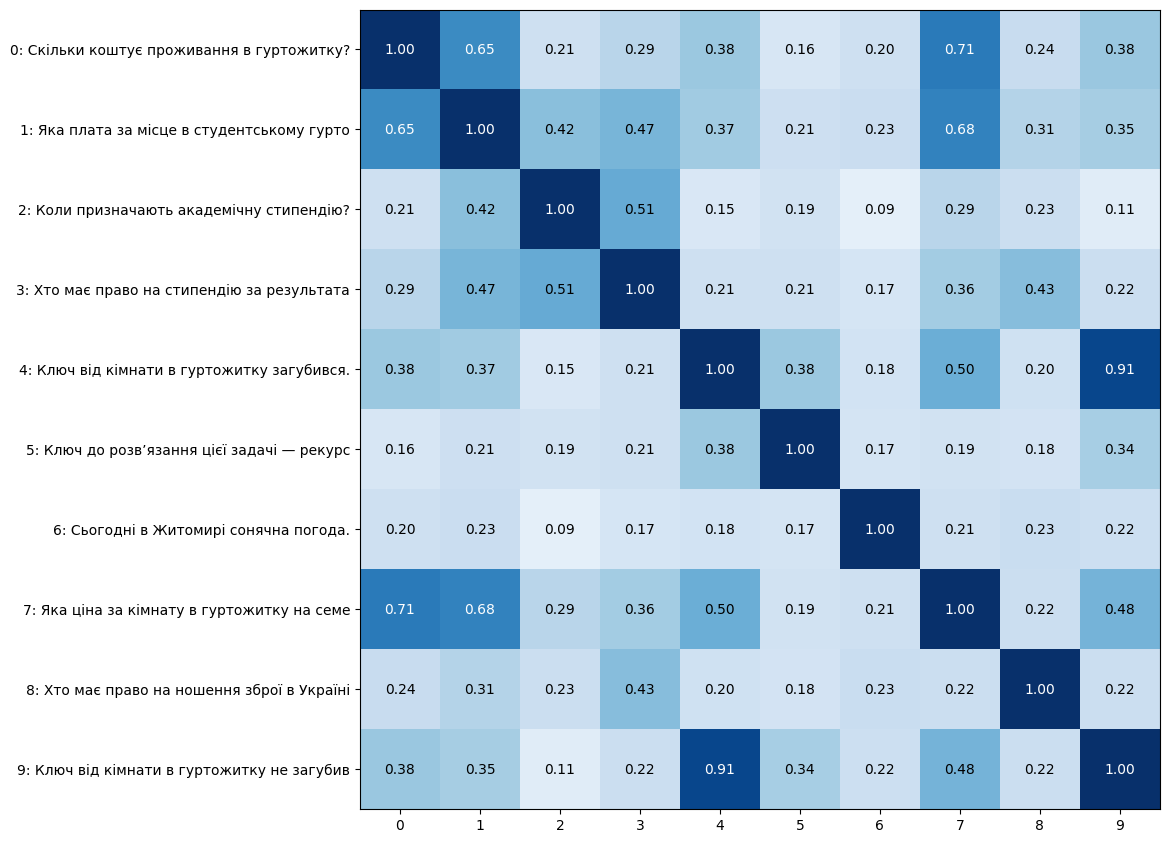

In [26]:
my_sentences = uni_sentences + [
    "Яка ціна за кімнату в гуртожитку на семестр?",         # 7: перефразування речення 0
    "Хто має право на ношення зброї в Україні?",              # 8: спільні слова з реченням 3, інший зміст
    "Ключ від кімнати в гуртожитку не загубився.",            # 9: заперечення речення 4
]
show_similarity_matrix(my_sentences, figsize=(11, 9))

**Коментар до матриці.**
- **Перефразування (7).** Речення «Яка ціна за кімнату в гуртожитку на семестр?» має подібність 0,71 з реченням 0 і 0,68 з реченням 1, хоча майже не має спільних слів із ними. Для порівняння, наступне за величиною значення в цьому рядку — 0,50 (з реченням 4). Тобто модель розпізнає той самий зміст у інших словах.
- **Спільні слова, інший зміст (8).** Речення «Хто має право на ношення зброї в Україні?» має з реченням 3 («Хто має право на стипендію…») подібність 0,43. Це найбільше значення в рядку 8 (решта від 0,18 до 0,31), тож збіг початку речення трохи підвищує подібність. Водночас 0,43 менше, ніж подібність справжньої пари за змістом (речення 2 і 3 — 0,51; речення 0 і 1 — 0,65). Збіг слів важить менше, ніж збіг змісту.
- **Заперечення (9).** Речення «Ключ від кімнати в гуртожитку не загубився.» має з реченням 4 («…загубився.») подібність 0,91. Це вище, ніж у будь-якої пари перефразувань у матриці (0,65 для пари 0 і 1, 0,71 для пари 0 і 7). Модель ембедингів майже не розрізняє твердження й його заперечення: обидва речення говорять про той самий ключ, ту саму кімнату й той самий гуртожиток, а слово «не» мало змінює вектор. Для задач, де заперечення важливе, самих ембедингів недостатньо, потрібна додаткова перевірка (наприклад, мовною моделлю).

### Питання 6

> Яким чином модель Qwen/Qwen3-Embedding-0.6B саботує проведення dance-battle в «Житомирській політехніці»? Як думаєте, чи зможете Ви підібрати ембедингову модель, яка буде притримуватися іншої думки?

**Відповідь.** У клітинці з трьома фразами (0 — «Танцюльки на денс-батлі», 1 — «Отримати гарну оцінку з СШІ», 2 — «Піти на перездачу») Qwen3-Embedding дає такі значення: денс-батл і гарна оцінка — **0,39**, денс-батл і перездача — **0,67**, гарна оцінка і перездача — 0,47. Тобто модель вважає денс-батл найближчим до перездачі й найдалі від гарної оцінки. «Саботаж» у цьому: у її просторі проведення денс-батлу асоціюється з поганим результатом і перездачею, а не з успішним навчанням і заохоченням студентів.

**Інші моделі.** Я порівняла ще дві моделі на тих самих фразах (клітинка нижче). `paraphrase-multilingual-MiniLM-L12-v2` дає 0,07 (денс-батл — оцінка), 0,50 (денс-батл — перездача) і 0,33 (оцінка — перездача): та сама тенденція, денс-батл найближчий до перездачі. `multilingual-e5-small` дає 0,85, 0,89 і 0,86: усі три пари майже однакові, але й тут найвище значення в денс-батлу з перездачею (0,89). Жодна з трьох перевірених моделей не змінила порядок. Тому за результатом цього експерименту підібрати модель з протилежною думкою не вдалося. Імовірніше це зробить інша, більша модель (наприклад, `BAAI/bge-m3` чи `multilingual-e5-large`), яку я не перевіряла. Значення в e5 стиснуті у вузький діапазон 0,85–0,89, тому порядок пар там мало показовий.

In [27]:
# Інші моделі можуть мати іншу «думку»: порівнюємо матриці подібності трьох фраз
other_models = {
    "Qwen/Qwen3-Embedding-0.6B": "",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2": "",
    "intfloat/multilingual-e5-small": "query: ",   # E5 вимагає префікс
}
np.set_printoptions(precision=2, suppress=True)
for name, prefix in other_models.items():
    m = SentenceTransformer(name, device=device)
    e = m.encode([prefix + s for s in pseudo_random_sentences], normalize_embeddings=True)
    print(name)
    print(e @ e.T, "\n")

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Qwen/Qwen3-Embedding-0.6B
[[1.01 0.39 0.67]
 [0.39 1.   0.47]
 [0.67 0.47 1.  ]] 



modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (21 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

intfloat/multilingual-e5-small
[[1.   0.85 0.89]
 [0.85 1.   0.86]
 [0.89 0.86 1.  ]] 



### Питання 7

> У розділі 5 «Тексти на площині» ембединги проєктують на площину методом головних компонент (PCA). Чому речення однієї теми групуються разом, хоча проєкція втрачає більшу частину інформації? Чи можна за відстанню між точками на графіку судити про справжню подібність текстів?

**Відповідь.** PCA обирає дві осі, уздовж яких розкид даних найбільший. У цьому наборі найбільше відрізняються між собою саме теми (гуртожиток, стипендія, оцінювання, інше), тому різниця між темами становить основну частину дисперсії й зберігається в перших двох компонентах, а дрібніші відмінності між реченнями однієї теми лежать у решті компонент і втрачаються. Тому групи видно навіть після проєкції. Судити про справжню подібність за відстанню між точками на графіку можна лише обережно: ортогональна проєкція не збільшує відстаней, отже далекі точки на графіку були далекими й у просторі з 1024 вимірів, а близькі точки на графіку можуть бути далекими в оригіналі, бо різниця пішла у відкинуті виміри. Для точного висновку слід використовувати косинусну подібність у повному просторі.

### Питання 8

> Порівняйте дві матриці подібності в розділі 6 «Запит і документ кодуються по-різному». Що змінює інструкція, яку модель додає до запиту?

**Відповідь.** Перша матриця отримана без промпту (`prompt_name=None`), друга з промптом `query`. Промпт — це текст `Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:`, який модель дописує на початок запиту; фрагменти кодуються без інструкції. Інструкція повідомляє моделі, що текст є пошуковим запитом, і зсуває його ембединг у бік ембедингів фрагментів із відповіддю.

**Що змінилося в цифрах.** Значення на діагоналі (правильні пари) зросли: 0,44 → 0,51, 0,69 → 0,76, 0,43 → 0,45, 0,38 → 0,40. Але зросли й подібності до неправильних фрагментів, наприклад у рядку 0 з 0,52 до 0,61. Запас між правильною парою і найближчою неправильною змінився по-різному: у рядку 1 він збільшився з 0,47 до 0,52, у рядку 3 — з 0,18 до 0,21, у рядку 2 зменшився з 0,28 до 0,25. Порядок правильних відповідей не змінився в жодному рядку: рядки 1–3 знаходять правильний фрагмент в обох матрицях, а рядок 0 («До якої дати платити?») обирає хибний фрагмент про тишу в обох (0,52 проти 0,44 без промпту й 0,61 проти 0,51 з промптом). Отже, інструкція підвищує подібність запиту до фрагментів загалом і не виправляє помилку в рядку 0, яку вирішує дописування назви документа в розділі 9.

### Питання 9

> Поставте в розділі 8 «Пошук вручну» три власні питання до документів університету. Чи потрапив правильний документ до трьох найближчих фрагментів? Порівняйте подібність найкращого фрагмента з подібністю для питання, на яке в документах немає відповіді.

Поставлено три питання з відповіддю в документах — про переведення з іншого університету (документ 283), про види порушень академічної доброчесності (документ 1199), про розмір стипендії ректора (документ 344) — і одне питання без відповіді (про басейн).

In [28]:
show("Чи можна перевестися з іншого університету на другий курс?", chunk_embeddings)
show("Які види порушень академічної доброчесності визначає кодекс?", chunk_embeddings)
show("Який розмір стипендії ректора?", chunk_embeddings)
show("Чи є в університеті басейн для студентів?", chunk_embeddings)   # відповіді в документах немає

Запит: Чи можна перевестися з іншого університету на другий курс?
  0.54  [3329] ОПП 121 «Інженерія програмного забезпечення» (бакалавр), редакція 2024 року
        триманих у інших університетах України, за умови відповідності їх набутих компетентностей. Міжнародна кредитна мобільність На основі двосторонніх дого…
  0.54  [277] Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
        ься обмеженнями, вказаними в п. 2.9, і враховує потенційні негативні наслідки такої зміни для забезпечення надання освітньої послуги за вибором інших …
  0.53  [348] Положення про користування гуртожитками
        итомирської політехніки до виконання будь-яких робіт з його благоустрою та/або прилеглої території може здійснюватися виключно за їх згодою. 4.9. Пред…

Запит: Які види порушень академічної доброчесності визначає кодекс?
  0.79  [1199] Кодекс академічної доброчесності
        ті……. 7 4. Етика академічних взаємовідносин ……………………………. 16 5. Види порушень академіч

**Результати.**

| Питання | Очікуваний документ | Знайдено в топ-3 | Подібність найкращого фрагмента |
|---|---|---|---|
| Переведення з іншого університету | 283 | 3329, 277, 348: **ні** | 0,54 |
| Види порушень академічної доброчесності | 1199 | 1199, 1199, 1199: так | 0,79 |
| Розмір стипендії ректора | 344 | 344, 340, 340: так | 0,63 |
| Басейн для студентів (відповіді немає) | немає | 1219, 1199, … | 0,51 |

Для питань про доброчесність і стипендію ректора правильний документ потрапив до трьох найближчих, і подібність найкращого фрагмента висока (0,79 і 0,63). Питання про переведення не знайшло документа 283, бо цей документ є сканом без текстового шару: ноутбук пропустив його (розділ 7: «текстового шару немає, потрібне OCR — пропущено»), тому в індексі його немає. Подібність найкращого фрагмента (0,54) майже збігається зі значенням для питання про басейн (0,51), хоча відповідь на питання про переведення в університетських документах існує. Значення подібності не розрізняє «відповіді в документах немає» і «документ не потрапив в індекс», тож універсального порога немає. Тому рішення про відсутність відповіді залишають генеративній моделі (розділ 6 демо 2), а відсутні документи виправляють розпізнаванням тексту (OCR).

### Питання 10

> Чому дописування назви документа на початок фрагмента (розділ 9) покращує пошук? Знайдіть приклад фрагмента, який без назви документа втрачає зміст.

**Відповідь.** Фрагмент, вирваний із середини документа, не містить слів, які задають тему всього документа. Назва документа повертає ці слова: ембединг фрагмента отримує контекст, і запит із цими словами стає ближчим до фрагмента.

**Приклад із ноутбука.** Фрагмент «Студент вносить авансовий платіж за 1 семестр до 1 вересня, а за 2 семестр – до 1 лютого» не містить слова «гуртожиток». Для запиту «До якої дати платити за гуртожиток?» без назви документа він мав подібність 0,51 і програвав фрагменту про тишу в гуртожитку (0,61). Після дописування назви «Положення про користування гуртожитками» подібність оплати зросла до 0,76, а подібність фрагмента про тишу залишилася майже незмінною (0,59). Так само фрагмент «З 23:00 години і до 7:00 години повинна додержуватись тиша» без назви не вказує, де діє це правило.